# Unsupervised anomaly detection on Mars HiRISE crops

NSSC 2026 | Data Analytics | IIT Kharagpur

End-to-end pipeline: ConvAE bottleneck (no pretrained weights), Isolation Forest on latents, MAD threshold, reconstruction heatmaps, and a join to the provided source metadata.

Related files: MODEL_CHANGELOG.md, REPORT.pdf, submission/.

**v3 numbers:** latent=512; threshold ~0.525 (MAD); flagged=242/10422; novelty = -IF.score_samples; contamination=auto (not used for the count).


## 0. Setup

C:\Users\Yasharka\AppData\Roaming\Python\Python313\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


device: cuda
10422 crops | 172 sources | 10422 jpg files


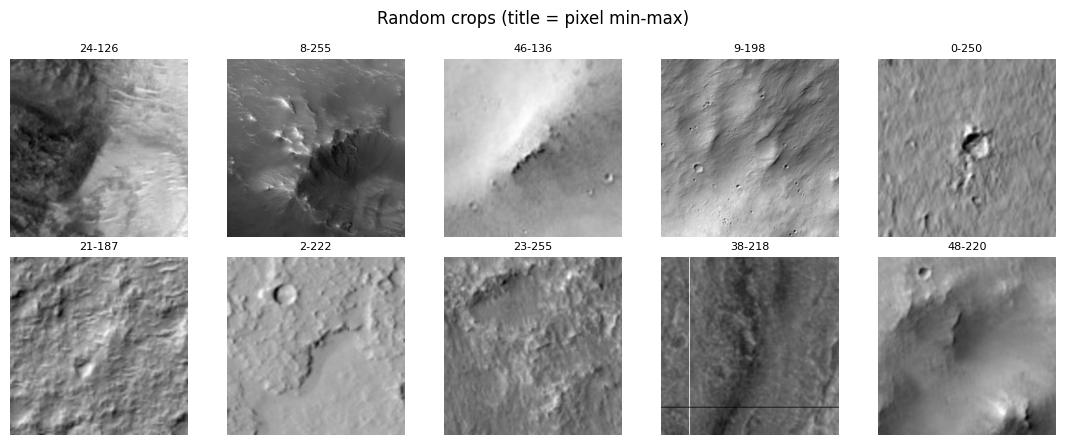

In [1]:

from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch

ROOT = Path('.').resolve()
sys.path.insert(0, str(ROOT / 'src'))
from dataset import HiRISEDataset
from model import ConvAutoencoder

IMG_DIR = ROOT / 'images' / 'images'
crop = pd.read_csv(ROOT / 'crop_metadata_index.csv')
src = pd.read_csv(ROOT / 'source_image_metadata.csv')
meta = json.loads((ROOT / 'submission/outputs/threshold_meta.json').read_text())
scored = pd.read_csv(ROOT / 'submission/outputs/scored_crops.csv')

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE)
print(len(crop), 'crops |', len(src), 'sources |', len(list(IMG_DIR.glob('*.jpg'))), 'jpg files')

fig, axes = plt.subplots(2, 5, figsize=(11, 4.5))
rng = np.random.RandomState(0)
for ax, i in zip(axes.ravel(), rng.choice(len(crop), 10, replace=False)):
    im = np.array(Image.open(IMG_DIR / crop.loc[i, 'filename']).convert('L'))
    ax.imshow(im, cmap='gray')
    ax.set_title(f'{im.min()}-{im.max()}', fontsize=8)
    ax.axis('off')
fig.suptitle('Random crops (title = pixel min-max)')
plt.tight_layout()
plt.show()


## Phase 1 — Autoencoder

### 1.1 Architecture

Custom ConvAE only (no pretrained weights).

- Pad 227→228, four stride-2 stages down to 14×14, 1×1 squeeze to 128 channels, FC → latent vector.
- Decoder: nearest upsample + two 3×3 convs per scale, final resize to 227.
- We use **latent_dim=512**. 128/256 underfit fine texture in earlier runs; 512 reconstructed dunes/craters better while still giving Isolation Forest a compact 1-D code.

See `src/model.py`.


In [2]:

ckpt = torch.load(ROOT / 'submission/checkpoints/cae_v3.pt', map_location=DEVICE, weights_only=False)
model = ConvAutoencoder(latent_dim=ckpt['latent_dim']).to(DEVICE)
sd = ckpt['model_state']
if ckpt.get('dtype') == 'float16':
    sd = {k: (v.float() if v.is_floating_point() else v) for k, v in sd.items()}
model.load_state_dict(sd)
model.eval()
print('latent_dim', ckpt['latent_dim'], '| params', sum(p.numel() for p in model.parameters()))
x = torch.randn(1, 1, 227, 227, device=DEVICE)
with torch.no_grad():
    r, z = model(x)
print('in', tuple(x.shape), 'latent', tuple(z.shape), 'recon', tuple(r.shape))


latent_dim 512 | params 27473505


in (1, 1, 227, 227) latent (1, 512) recon (1, 1, 227, 227)


### 1.2 Loss

Final mix after fine-tune: **0.40 MSE + 0.35 (1−SSIM) + 0.25 gradient L1**.

MSE alone smoothed ridgelines (v1). SSIM helps structure. Gradient L1 (finite differences) pushes edges without a VGG/ResNet perceptual net. Short MSE warmup first so training does not diverge.

![train](submission/figures/01_training_curve.png)

MSE stays flat/low. The steps in the right panel are from turning on SSIM/grad (and later the fine-tune weights), not from the optimiser diverging.

![recon](submission/figures/02_reconstructions.png)


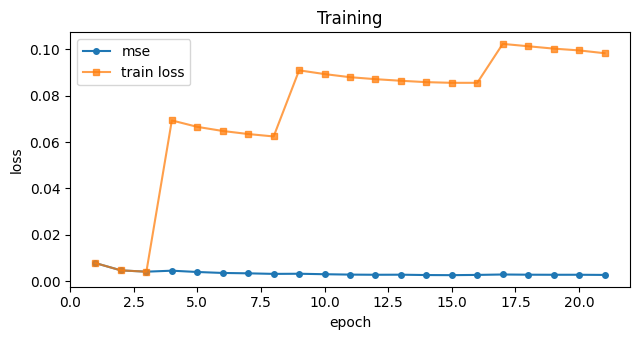

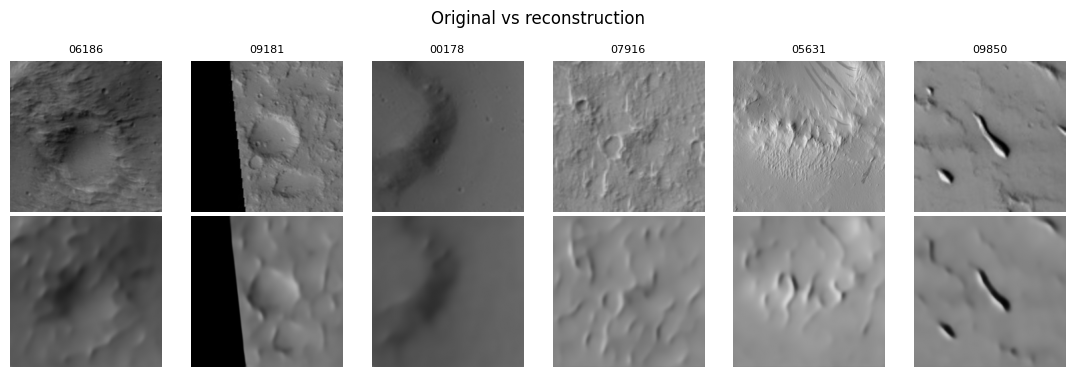

In [3]:

hist = pd.read_csv(ROOT / 'submission/outputs/train_history.csv')
plt.figure(figsize=(6.5, 3.5))
plt.plot(hist['epoch'], hist['mse'], '-o', ms=4, label='mse')
plt.plot(hist['epoch'], hist['loss'], '-s', ms=4, alpha=0.75, label='train loss')
plt.xlabel('epoch'); plt.ylabel('loss'); plt.legend(); plt.title('Training')
plt.tight_layout(); plt.show()

ds = HiRISEDataset(IMG_DIR, ROOT / 'crop_metadata_index.csv', preload=False)
fig, axes = plt.subplots(2, 6, figsize=(11, 3.8))
idxs = np.random.RandomState(1).choice(len(ds), 6, replace=False)
with torch.no_grad():
    for i, idx in enumerate(idxs):
        x, name, _ = ds[idx]
        recon, _ = model(x.unsqueeze(0).to(DEVICE))
        axes[0, i].imshow(x.squeeze().numpy(), cmap='gray', vmin=0, vmax=1)
        axes[0, i].set_title(name[7:12], fontsize=8); axes[0, i].axis('off')
        axes[1, i].imshow(recon.squeeze().cpu().numpy(), cmap='gray', vmin=0, vmax=1)
        axes[1, i].axis('off')
axes[0, 0].set_ylabel('orig'); axes[1, 0].set_ylabel('recon')
plt.suptitle('Original vs reconstruction')
plt.tight_layout(); plt.show()


### 1.3 Latent visualisation

t-SNE on a 3k subsample of standardised latents. Treated as a sanity check only — not geological labels, not proof of collapse.

![tsne](submission/figures/03_tsne_latent.png)


Z (10422, 512)


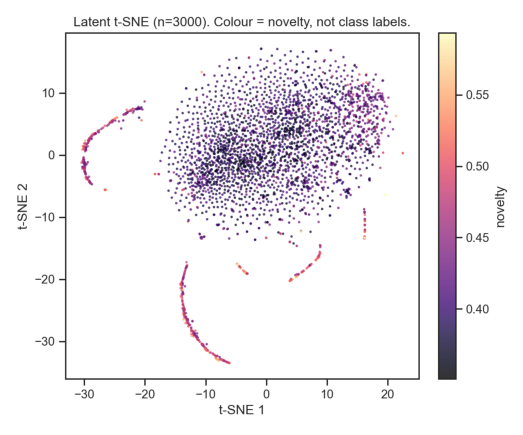

In [4]:

Z = np.load(ROOT / 'submission/outputs/latents.npy')
print('Z', Z.shape)
img = Image.open(ROOT / 'submission/figures/03_tsne_latent.png')
plt.figure(figsize=(6.5, 5.5)); plt.imshow(img); plt.axis('off'); plt.show()


## Phase 2 — Isolation Forest

### 2.1 Scoring

Fit IF on standardised latents (`n_estimators=400`, `contamination='auto'`).

Sklearn’s `score_samples` is higher for inliers, so we use:

`novelty = -score_samples`  → higher means more anomalous.

### 2.2 Threshold

Not top-N. We look at:

- elbow on the sorted novelty curve (max distance to the chord)
- modified z-score via median/MAD
- μ+2.5σ as a reference (histogram is skewed, so we do not treat Gaussian as gospel)

**Chosen threshold = 0.525258** (rule: `robust`), **242** crops flagged.

Elbow is shown as a reference (~rank 517). Final cut is **MAD (k=3.5)**, which is stricter than the elbow count. Contamination does not decide this count.

![thr](submission/figures/04_novelty_threshold.png)


In [5]:

print(json.dumps(meta, indent=2))
flagged = scored[scored['is_anomaly']].sort_values('novelty_score', ascending=False)
print('flagged', len(flagged))
flagged[['filename','source_image_id','novelty_score','recon_mse','latitude','longitude','season']].head(10)


{
  "median": 0.4023415864462856,
  "mad": 0.023687803804995848,
  "mu": 0.4133419649633402,
  "sigma": 0.04259128156112443,
  "elbow_idx": 517,
  "elbow_threshold": 0.5029799650545979,
  "robust_threshold": 0.5252582852120165,
  "gauss_2p5": 0.5198201688661512,
  "final_threshold": 0.5252582852120165,
  "threshold_rule": "robust",
  "n_flagged": 242,
  "k_modified_z": 3.5,
  "isolation_forest_contamination": "auto",
  "n_flagged_fused": 298,
  "fused_threshold_gauss_2p5": 0.5206421384553619,
  "flag_overlap_image_vs_fused": 221
}
flagged 242


,filename,source_image_id,novelty_score,recon_mse,latitude,longitude,season
2052,sample_02053.jpg,SRC_064,0.597193,0.003011,90.0,0.0,N-spring
8662,sample_08663.jpg,SRC_097,0.594107,0.001637,0.0,180.0,N-winter
10202,sample_10203.jpg,SRC_166,0.593393,0.003057,90.0,0.0,N-spring
3224,sample_03225.jpg,SRC_039,0.593348,0.005903,90.0,0.0,N-summer
1979,sample_01980.jpg,SRC_044,0.593014,0.002024,-90.0,0.0,N-autumn
4585,sample_04586.jpg,SRC_022,0.590090,0.006342,20.0,180.0,N-spring
9549,sample_09550.jpg,SRC_164,0.590030,0.002745,20.0,180.0,N-autumn
4937,sample_04938.jpg,SRC_049,0.589178,0.001974,5.0,180.0,N-spring
2963,sample_02964.jpg,SRC_119,0.588191,0.003542,90.0,0.0,N-spring
6423,sample_06424.jpg,SRC_039,0.587494,0.004234,90.0,0.0,N-summer


### 2.3 Location

Join on `source_image_id`. Provided source longitudes are only **0 or 180**, so we do not treat a lon–lat scatter as a planetary map. Compare flagged vs all on latitude, sun_angle, and season.

![meta](submission/figures/05_geo_anomalies.png)

![coords](submission/figures/05b_source_coords.png)


season
N-spring    107
N-summer     70
N-winter     33
N-autumn     32
Name: count, dtype: int64
sun_angle flagged vs all: 52.68 55.31
unique sources flagged: 83
unique longitudes in metadata: [0.0, 180.0]


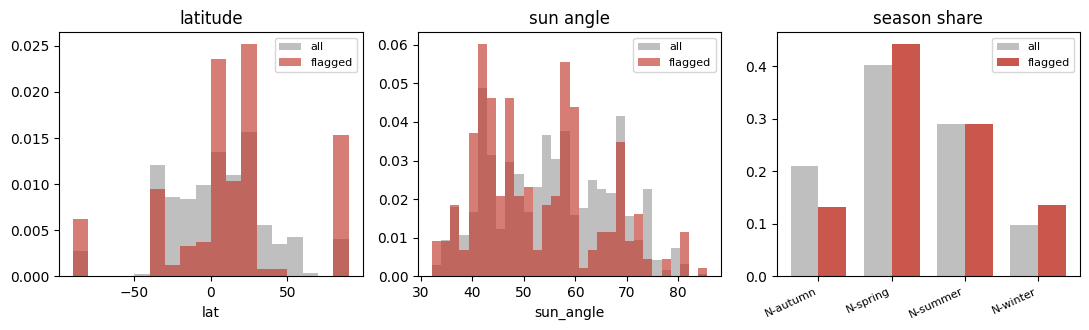

In [6]:

flg = scored[scored['is_anomaly']]
print(flg['season'].value_counts())
print('sun_angle flagged vs all:', round(flg['sun_angle'].mean(), 2), round(scored['sun_angle'].mean(), 2))
print('unique sources flagged:', flg['source_image_id'].nunique())
print('unique longitudes in metadata:', sorted(scored['longitude'].dropna().unique().tolist()))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
axes[0].hist(scored['latitude'], bins=18, color='0.75', density=True, label='all')
axes[0].hist(flg['latitude'], bins=18, color='#c0392b', alpha=0.65, density=True, label='flagged')
axes[0].set_xlabel('lat'); axes[0].legend(fontsize=8); axes[0].set_title('latitude')
axes[1].hist(scored['sun_angle'], bins=30, color='0.75', density=True, label='all')
axes[1].hist(flg['sun_angle'], bins=30, color='#c0392b', alpha=0.65, density=True, label='flagged')
axes[1].set_xlabel('sun_angle'); axes[1].legend(fontsize=8); axes[1].set_title('sun angle')
seasons = sorted(scored['season'].dropna().unique())
all_c = scored['season'].value_counts(normalize=True).reindex(seasons).fillna(0)
flg_c = flg['season'].value_counts(normalize=True).reindex(seasons).fillna(0)
x = np.arange(len(seasons)); w = 0.38
axes[2].bar(x - w/2, all_c.values, w, color='0.75', label='all')
axes[2].bar(x + w/2, flg_c.values, w, color='#c0392b', alpha=0.85, label='flagged')
axes[2].set_xticks(x); axes[2].set_xticklabels(seasons, rotation=25, ha='right', fontsize=8)
axes[2].set_title('season share'); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()


### 2.4 Metadata fusion (optional)

Concatenate the image latent with normalised sun angle, lat/lon, resolution, and season one-hots; refit Isolation Forest. Fused novelty is again -score_samples. Cut fused scores at μ+2.5σ (scale differs from image-only MAD).

| Pipeline | Flags |
|----------|------:|
| Image-only (MAD τ) | 242 |
| Fused (μ+2.5σ) | 298 |
| Overlap | 221 |
| Image-only exclusive / fused-only exclusive | 21 / 77 |

Primary pipeline stays image-latent only. Fusion can nudge borderline ranks via acquisition context; it should not invent the official anomaly list.


In [ ]:
from IPython.display import Image, display
p = ROOT / 'submission/figures/07_fusion_compare.png'
if p.exists():
    display(Image(filename=str(p)))
else:
    print('fusion figure not found — run train_and_analyze / plots after scoring')


## Phase 3 — Heatmaps

### 3.1

Take crops with novelty ≥ threshold, sort by novelty, keep top 5. Reconstruct and plot `|x - x̂|`.

![hm](submission/figures/06_top5_heatmaps.png)

### 3.2 Hypotheses (not labels)

| # | file | novelty | guess |
|---|------|--------:|-------|
| 1 | `sample_02053.jpg` | 0.5972 | Dark band / streaks — looks like a crop mask or sensor streak; error sits on the streak and bright contacts. |
| 2 | `sample_08663.jpg` | 0.5941 | Blotchy texture the AE cannot pin down — possible domain shift / non-typical content. |
| 3 | `sample_10203.jpg` | 0.5934 | Dense ripples, error everywhere — rare dune fabric or a high-frequency splice. |
| 4 | `sample_03225.jpg` | 0.5933 | Round mound + edge error + bottom mask — seam/splice hypothesis. |
| 5 | `sample_01980.jpg` | 0.5930 | Speckled bumps, patchy error islands — local corruption / pasted patches. |

Several of these show a hard black strip on the crop border — that pattern fits injected sensor/crop artifacts better than continuous geology.


,filename,source_image_id,novelty_score,recon_mse,is_anomaly,robust_z
0,sample_02053.jpg,SRC_064,0.597193,0.003011,True,5.548314
1,sample_08663.jpg,SRC_097,0.594107,0.001637,True,5.460425
2,sample_10203.jpg,SRC_166,0.593393,0.003057,True,5.440115
3,sample_03225.jpg,SRC_039,0.593348,0.005903,True,5.438826
4,sample_01980.jpg,SRC_044,0.593014,0.002024,True,5.429309


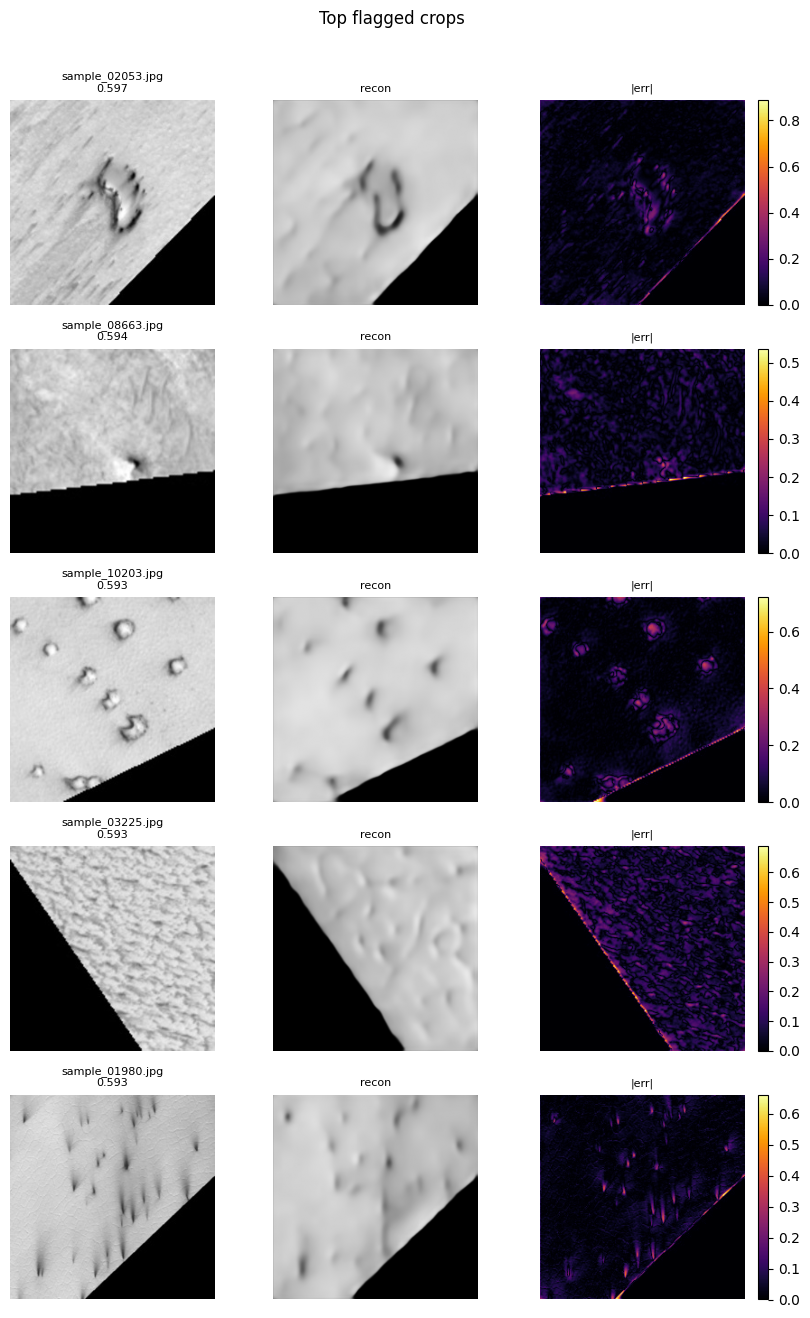

In [7]:

top = pd.read_csv(ROOT / 'submission/outputs/top5_anomalies.csv')
display(top)

name_to_idx = {n: i for i, n in enumerate(ds.filenames)}
fig, axes = plt.subplots(len(top), 3, figsize=(8.5, 2.6 * len(top)))
with torch.no_grad():
    for r_i, (_, row) in enumerate(top.iterrows()):
        x, _, _ = ds[name_to_idx[row['filename']]]
        recon, _ = model(x.unsqueeze(0).to(DEVICE))
        x_np = x.squeeze().numpy()
        r_np = recon.squeeze().cpu().numpy()
        err = np.abs(x_np - r_np)
        axes[r_i, 0].imshow(x_np, cmap='gray', vmin=0, vmax=1)
        axes[r_i, 0].set_title(f"{row['filename']}\n{row['novelty_score']:.3f}", fontsize=8)
        axes[r_i, 1].imshow(r_np, cmap='gray', vmin=0, vmax=1)
        axes[r_i, 1].set_title('recon', fontsize=8)
        im = axes[r_i, 2].imshow(err, cmap='inferno')
        axes[r_i, 2].set_title('|err|', fontsize=8)
        for ax in axes[r_i]:
            ax.axis('off')
        fig.colorbar(im, ax=axes[r_i, 2], fraction=0.046)
plt.suptitle('Top flagged crops', y=1.01)
plt.tight_layout()
plt.show()


## Phase 4 — Iteration log

See `MODEL_CHANGELOG.md` (v1 MSE/128 → v2 deeper+SSIM/256 → v3 14×14 map, latent 512, SSIM+grad, thresholding).
